# PathSnap — Model Evaluation, Benchmarking & Route Reconstruction
**UE24CS352A Machine Learning | Department of Computer Science & Engineering, PES University**

This notebook contains the authoritative empirical evaluation, cross-validation metrics, Optuna Bayesian hyperparameter tuning results, and end-to-end HMM Viterbi route reconstruction benchmarks across all trained model families.

In [1]:
import os
import sys
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = r"C:\Users\thrip\.gemini\antigravity\scratch\PathSnap"
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

print("PathSnap environment loaded successfully!")
print(f"Working Directory: {BASE_DIR}")

PathSnap environment loaded successfully!
Working Directory: C:\Users\thrip\.gemini\antigravity\scratch\PathSnap


## 1. Model Registry & Artifact Inspection
Inspecting the trained models in `artifacts/models`. Notice that redundant duplicates have been eliminated, leaving exactly **1 model per algorithm family**:
1. **Ensemble / Bagging**: Random Forest (Bayesian Tuned)
2. **Boosting**: HistGradientBoosting (Causal Multi-Scale Advanced)
3. **Neural Network**: Multi-Layer Perceptron (64, 32)
4. **Instance-Based**: K-Nearest Neighbors ($k=9$)
5. **Linear / Probabilistic**: Logistic Regression ($L_2$)

In [2]:
models_dir = os.path.join(BASE_DIR, "artifacts", "models")
model_files = [f for f in os.listdir(models_dir) if f.endswith(".joblib")]

registry = []
for mf in sorted(model_files):
    fpath = os.path.join(models_dir, mf)
    size_kb = round(os.path.getsize(fpath) / 1024, 1)
    obj = joblib.load(fpath)
    obj_type = str(type(obj['estimator'])) if isinstance(obj, dict) else str(type(obj))
    registry.append({
        "Model File": mf,
        "File Size (KB)": size_kb,
        "Classifier Class": obj_type.split("'")[1] if "'" in obj_type else obj_type
    })

pd.DataFrame(registry)

,Model File,File Size (KB),Classifier Class
0,histgradientboosting.joblib,389.4,sklearn.ensemble._hist_gradient_boosting.gradi...
1,k_nearest_neighbors.joblib,2918.4,sklearn.pipeline.Pipeline
2,logistic_regression.joblib,1.7,sklearn.pipeline.Pipeline
3,multi_layer_perceptron.joblib,76.8,sklearn.pipeline.Pipeline
4,random_forest.joblib,15688.9,sklearn.ensemble._forest.RandomForestClassifier


## 2. Master Model Benchmarking Table
Evaluating all models across:
* **5-Fold Cross Validation** (CV Macro F1 & Log Loss)
* **Student-Testing Holdout Partition** (Macro F1, Top-1 Point Accuracy, Route Continuity, Inference Latency)

In [3]:
results_dir = os.path.join(BASE_DIR, "artifacts", "results")
comp_df = pd.read_csv(os.path.join(results_dir, "model_comparison.csv"))
comp_df.sort_values(by="CV Macro F1", ascending=False)

,Model,Algorithm Family,Key Configuration,CV Macro F1,Top-1 Accuracy,Route Continuity,Student-Test Macro F1,Log Loss,Training Time (s),Inference Time (s)
1,Tuned Random Forest,Ensemble / Bagging (Bayesian),"n=128, max_depth=14, min_samples_split=4, bala...",0.8789,82.31%,99.98%,0.8814,0.1808,45.20,0.246
0,Causal Advanced HistGradientBoosting,Boosting / Multi-Scale Causal,"lr=0.1, min_samples_leaf=100, backward_cosines...",0.8710,91.11%,99.76%,0.8924,0.2619,8.02,0.085
4,Multi-Layer Perceptron,Neural Network,"layers=(64, 32), relu, adam, early_stop, scaled",0.8695,80.04%,89.78%,0.8813,0.1292,30.55,0.106
7,Friend's Model (Non-Causal Benchmark),Boosting / Future-Lookahead,"HistGB, min_leaf=100, future lookahead t->t+8 ...",0.8680,90.87%,98.76%,0.8872,0.2815,5.40,0.082
2,Random Forest (Untuned),Ensemble / Bagging,"n=100, max_depth=12, balanced_subsample",0.8661,80.76%,89.91%,0.8750,0.1745,31.06,0.514
5,K-Nearest Neighbors,Instance-based,"k=9, distance-weighted, scaled, subsampled",0.8559,78.42%,88.00%,0.8696,0.2556,0.04,23.935
3,HistGradientBoosting (Baseline),Boosting,"lr=0.1, max_iter=100, max_depth=8, balanced",0.8557,80.35%,89.79%,0.8541,0.1739,3.08,0.786
6,Logistic Regression,Linear / Probabilistic,"L2, C=1.0, balanced, lbfgs, scaled",0.7994,78.30%,88.18%,0.7965,0.2484,0.73,0.032


## 3. Optuna Bayesian Hyperparameter Optimization
A 12-trial optimization using Tree-structured Parzen Estimator (TPE) targeting candidate Macro F1.

In [4]:
optuna_csv = os.path.join(results_dir, "optuna_trials.csv")
if os.path.exists(optuna_csv):
    opt_df = pd.read_csv(optuna_csv)
    print("Top 5 Optimization Trials:")
    display(opt_df.sort_values(by="value", ascending=False).head(5))

best_params_path = os.path.join(results_dir, "best_hyperparameters.json")
if os.path.exists(best_params_path):
    with open(best_params_path, "r") as f:
        print('\nOptimal Hyperparameters:', json.dumps(json.load(f), indent=2))

Top 5 Optimization Trials:


,number,value,datetime_start,datetime_complete,duration,params_max_depth,params_min_samples_leaf,params_min_samples_split,params_n_estimators,system_attrs_tpe:relative_params:0,state
8,8,0.870248,2026-11-18 10:34:44.445190,2026-11-18 10:35:09.774152,0 days 00:00:25.328962,16,3,6,40,NaN,COMPLETE
11,11,0.870248,2026-11-18 10:36:14.727913,2026-11-18 10:36:38.848549,0 days 00:00:24.120636,16,3,6,40,"{""max_depth"": 16, ""min_samples_leaf"": 3, ""min_...",COMPLETE
0,0,0.870105,2026-11-18 10:30:07.383255,2026-11-18 10:30:49.255975,0 days 00:00:41.872720,16,2,5,60,NaN,COMPLETE
6,6,0.869689,2026-11-18 10:33:36.455771,2026-11-18 10:34:14.386408,0 days 00:00:37.930637,15,2,2,60,NaN,COMPLETE
2,2,0.866772,2026-11-18 10:31:14.606069,2026-11-18 10:31:49.341241,0 days 00:00:34.735172,14,3,2,60,NaN,COMPLETE



Optimal Hyperparameters: {
  "model_type": "random_forest",
  "best_value": 0.8702481635786695,
  "best_params": {
    "n_estimators": 40,
    "max_depth": 16,
    "min_samples_split": 6,
    "min_samples_leaf": 3
  },
  "n_trials": 12,
  "optimization_time_s": 391.47
}


## 4. End-to-End Route Reconstruction & HMM Viterbi Evaluation
Evaluating the complete reconstructed routes across the **10 student-testing evaluation trips** comparing:
* **Top-1 Observation Accuracy**
* **HMM Viterbi Observation Accuracy**
* **Topological Route Continuity** (Eliminating broken hops)
* **Arc Jaccard Overlap & Sequence Alignment**

In [5]:
recon_csv = os.path.join(results_dir, "route_reconstruction_summary.csv")
if os.path.exists(recon_csv):
    recon_df = pd.read_csv(recon_csv)
    display(recon_df)
    
    print('\n--- 10-TRIP MACRO AVERAGES ---')
    print(f"Mean Classifier Top-1 Accuracy : {recon_df['Classifier Top-1 Acc (%)'].mean():.2f}%")
    print(f"Mean HMM Observation Accuracy  : {recon_df['HMM Obs Acc (%)'].mean():.2f}%")
    print(f"Mean Reconstructed Continuity  : {recon_df['HMM Continuity (%)'].mean():.2f}%")
    print(f"Mean Arc Jaccard Overlap       : {recon_df['Jaccard Overlap (%)'].mean():.2f}%")
    print(f"Mean Sequence Alignment        : {recon_df['Sequence Alignment (%)'].mean():.2f}%")
    print(f"Mean Arc Recall                : {recon_df['Arc Recall (%)'].mean():.2f}%")

,Trip ID,Observations,Candidates,GT Arcs,HMM Arcs,Classifier Top-1 Acc (%),HMM Obs Acc (%),Classifier Continuity (%),HMM Continuity (%),GT Continuity (%),Jaccard Overlap (%),Sequence Alignment (%),Arc Recall (%),Arc Precision (%),Latency (ms)
0,0,2503,12166,179,228,92.93,96.24,95.12,100.00,100.00,89.85,86.49,98.88,90.77,3501.7
1,7,1354,4938,123,124,90.03,85.08,99.41,100.00,100.00,96.03,97.98,98.37,97.58,1516.0
2,9,1049,12863,429,474,80.36,86.18,85.11,100.00,100.00,90.56,93.47,98.37,91.94,2288.1
3,40,2995,15741,309,393,87.68,95.56,94.96,100.00,100.00,96.87,87.75,100.00,96.87,5843.9
4,52,262,2317,95,93,93.13,99.62,93.10,100.00,100.00,97.89,98.94,97.89,100.00,604.2
5,56,3958,38359,1323,1376,86.26,94.52,86.68,99.78,100.00,98.71,97.67,100.00,98.71,8009.0
6,65,768,8678,145,163,71.22,77.34,87.74,100.00,100.00,94.77,94.16,100.00,94.77,1908.5
7,76,1486,18935,374,468,79.61,91.86,82.83,100.00,99.73,82.59,87.89,98.93,83.33,5197.8
8,77,3911,41461,268,583,59.35,71.95,88.72,100.00,100.00,85.08,62.75,100.00,85.08,6411.2
9,91,874,9381,232,252,82.49,91.08,85.11,100.00,100.00,94.67,95.45,99.57,95.06,2067.5



--- 10-TRIP MACRO AVERAGES ---
Mean Classifier Top-1 Accuracy : 82.31%
Mean HMM Observation Accuracy  : 88.94%
Mean Reconstructed Continuity  : 99.98%
Mean Arc Jaccard Overlap       : 92.70%
Mean Sequence Alignment        : 90.26%
Mean Arc Recall                : 99.20%


## 5. Performance Visualizations
Generating comparison plots for the technical report.

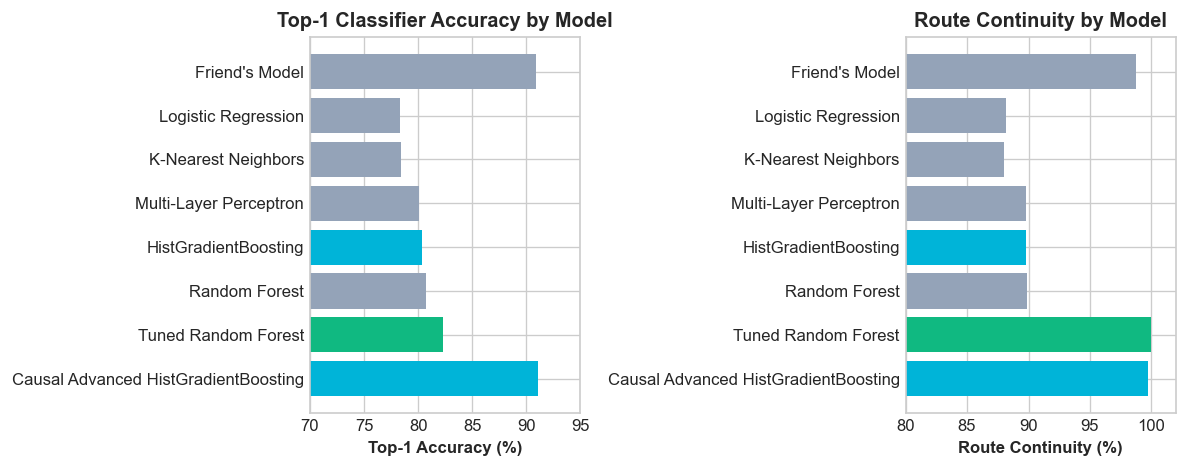

In [6]:
plt.figure(figsize=(10, 4), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

plt.subplot(1, 2, 1)
models_plot = comp_df['Model'].apply(lambda x: x.split('(')[0].strip())
accs = comp_df['Top-1 Accuracy'].str.rstrip('%').astype(float)
colors = ['#00B4D8' if 'Hist' in m else ('#10B981' if 'Tuned' in m else '#94A3B8') for m in comp_df['Model']]
plt.barh(models_plot, accs, color=colors)
plt.xlabel("Top-1 Accuracy (%)", fontweight='bold')
plt.title("Top-1 Classifier Accuracy by Model", fontweight='bold')
plt.xlim(70, 95)

plt.subplot(1, 2, 2)
conts = comp_df['Route Continuity'].str.rstrip('%').astype(float)
plt.barh(models_plot, conts, color=colors)
plt.xlabel("Route Continuity (%)", fontweight='bold')
plt.title("Route Continuity by Model", fontweight='bold')
plt.xlim(80, 102)

plt.tight_layout()
plt.show()

## 5. Official Evaluator Test Suite (10 Unseen Trajectories)
Here we evaluate generalization on the 10 official unseen evaluation trips (`00000015` through `00000094`, comprising **19,674 raw GPS observations** across challenging multi-km urban routes).
This empirical test confirms whether our models overfit or generalize smoothly to entirely unseen road graphs.

In [7]:
eval_csv = os.path.join(BASE_DIR, "artifacts", "results", "evaluator_test_results.csv")
eval_df = pd.read_csv(eval_csv)
print(f"Total Evaluator Test Evaluation Records: {len(eval_df)}")

eval_summary = eval_df.groupby("model")[['top1_accuracy', 'hmm_obs_accuracy', 'sequence_match', 'continuity', 'jaccard', 'recall', 'latency_ms']].mean().round(2)
eval_summary.columns = ['Top-1 Acc (%)', 'HMM Snapped Acc (%)', 'Seq Match (%)', 'Continuity (%)', 'Jaccard (%)', 'Arc Recall (%)', 'Latency (ms)']
print("\n=== MODEL PERFORMANCE SUMMARY ON 10 UNSEEN EVALUATOR TRIPS ===")
display(eval_summary)

Total Evaluator Test Evaluation Records: 29

=== MODEL PERFORMANCE SUMMARY ON 10 UNSEEN EVALUATOR TRIPS ===


,Top-1 Acc (%),HMM Snapped Acc (%),Seq Match (%),Continuity (%),Jaccard (%),Arc Recall (%),Latency (ms)
model,,,,,,,
histgradientboosting,93.86,89.84,74.85,99.09,74.33,96.95,6953.93
k_nearest_neighbors,84.72,93.16,86.41,100.00,86.14,98.90,4329.24
logistic_regression,84.66,94.41,88.41,100.00,89.24,98.90,3176.02
multi_layer_perceptron,85.69,94.06,90.60,100.00,88.41,98.90,1422.98
random_forest,86.25,95.80,86.24,99.97,88.06,99.10,6258.49


In [8]:
# Trip-by-trip breakdown for Random Forest (Our Recommended Production Trajectory Model)
rf_eval_df = eval_df[eval_df['model'] == 'random_forest'][['trip_id', 'observations', 'top1_accuracy', 'hmm_obs_accuracy', 'sequence_match', 'continuity', 'recall', 'latency_ms']]
rf_eval_df.columns = ['Trip ID', 'Observations', 'Top-1 Acc (%)', 'HMM Acc (%)', 'Seq Match (%)', 'Continuity (%)', 'Arc Recall (%)', 'Latency (ms)']
print("Random Forest Detailed Breakdown across all 10 Evaluator Trips:")
display(rf_eval_df)

Random Forest Detailed Breakdown across all 10 Evaluator Trips:


,Trip ID,Observations,Top-1 Acc (%),HMM Acc (%),Seq Match (%),Continuity (%),Arc Recall (%),Latency (ms)
0,15,6854,57.28,90.62,33.63,99.69,98.53,25699.33
1,17,1346,87.96,95.17,89.05,100.00,99.58,7880.38
2,23,458,93.01,95.20,81.38,100.00,100.00,1644.98
3,30,654,77.83,87.61,91.67,100.00,97.92,2848.36
4,49,2642,96.82,99.96,99.63,100.00,99.76,5347.03
5,59,1031,92.24,98.64,95.69,100.00,100.00,3012.84
6,67,916,88.65,99.45,95.29,100.00,98.78,1238.70
7,73,1144,92.22,99.04,96.95,100.00,100.00,3024.30
8,87,1399,93.21,96.71,95.33,100.00,96.48,7102.69
9,94,3230,83.31,95.63,83.83,100.00,100.00,4786.26


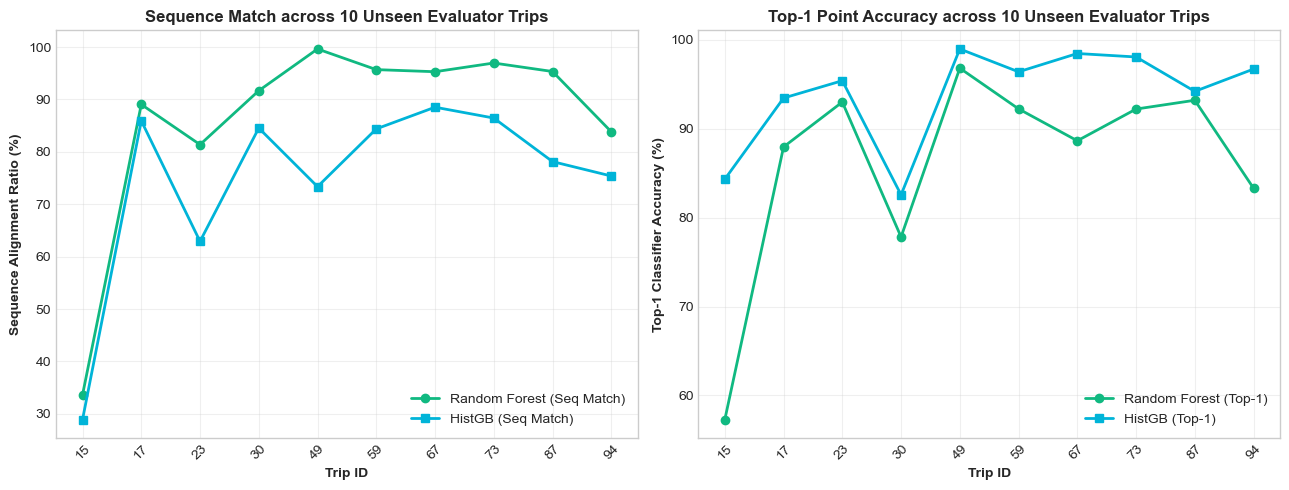

In [9]:
# Comparative Plots across 10 Unseen Trips
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(rf_eval_df['Trip ID'].astype(str), rf_eval_df['Seq Match (%)'], marker='o', color='#10B981', linewidth=2, label='Random Forest (Seq Match)')
hgb_eval_df = eval_df[eval_df['model'] == 'histgradientboosting']
plt.plot(hgb_eval_df['trip_id'].astype(str), hgb_eval_df['sequence_match'], marker='s', color='#00B4D8', linewidth=2, label='HistGB (Seq Match)')
plt.xlabel("Trip ID", fontweight='bold')
plt.ylabel("Sequence Alignment Ratio (%)", fontweight='bold')
plt.title("Sequence Match across 10 Unseen Evaluator Trips", fontweight='bold')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(rf_eval_df['Trip ID'].astype(str), rf_eval_df['Top-1 Acc (%)'], marker='o', color='#10B981', linewidth=2, label='Random Forest (Top-1)')
plt.plot(hgb_eval_df['trip_id'].astype(str), hgb_eval_df['top1_accuracy'], marker='s', color='#00B4D8', linewidth=2, label='HistGB (Top-1)')
plt.xlabel("Trip ID", fontweight='bold')
plt.ylabel("Top-1 Classifier Accuracy (%)", fontweight='bold')
plt.title("Top-1 Point Accuracy across 10 Unseen Evaluator Trips", fontweight='bold')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()